In [1]:
import pandas as pd
import numpy as np
nc = pd.read_csv(r"C:\Users\acann\OneDrive\Desktop\mtech major project\Anwesha Chakraborty\data\10 years data\MASTER_NC_2016_2023.csv")

vidp = pd.read_csv(r"C:\Users\acann\OneDrive\Desktop\mtech major project\Anwesha Chakraborty\data\10 years data\VIDP.csv", skiprows=5)

era5_existing = pd.read_csv(r"C:\Users\acann\OneDrive\Desktop\mtech major project\Anwesha Chakraborty\output\Final_Dataset_ERA5.csv")
nc["Datetime"] = pd.to_datetime(
    nc["Datetime"],
    errors="coerce"
)

vidp["valid"] = pd.to_datetime(
    vidp["valid"],
    errors="coerce"
)

era5_existing["Datetime"] = pd.to_datetime(
    era5_existing["Datetime"],
    errors="coerce"
)
# Rename columns
vidp = vidp.rename(columns={
    "valid": "Datetime",
    "vsby": "Visibility_miles"
})

# Convert visibility to numeric
# Non-numeric values such as "M" become NaN
vidp["Visibility_miles"] = pd.to_numeric(
    vidp["Visibility_miles"],
    errors="coerce"
)

# Convert miles to metres
vidp["Visibility"] = (
    vidp["Visibility_miles"] * 1609.344
)
# ERA5 data is hourly.
# Floor airport observation times to the hour.

vidp["Datetime"] = vidp["Datetime"].dt.floor("h")

# If multiple observations fall in the same hour,
# take their mean.
vidp_hourly = (
    vidp
    .groupby("Datetime", as_index=False)["Visibility"]
    .mean()
)
nc = nc[
    (nc["Datetime"] >= "2016-01-01") &
    (nc["Datetime"] < "2024-01-01")
].copy()

nc_master = nc.merge(
    vidp_hourly,
    on="Datetime",
    how="left"
)
nc_master = nc_master[
    [
        "Datetime",
        "Visibility",
        "Temperature",
        "RH",
        "WindSpeed",
        "BLH"
    ]
]
era5_2024_2025 = era5_existing[
    (era5_existing["Datetime"] >= "2024-01-01") &
    (era5_existing["Datetime"] < "2026-01-01")
].copy()


# Keep only required columns
era5_2024_2025 = era5_2024_2025[
    [
        "Datetime",
        "Visibility",
        "Temperature",
        "RH",
        "WindSpeed",
        "BLH"
    ]
]
MASTER_10YEAR = pd.concat(
    [
        nc_master,
        era5_2024_2025
    ],
    ignore_index=True
)

MASTER_10YEAR = (
    MASTER_10YEAR
    .sort_values("Datetime")
    .reset_index(drop=True)
)
MASTER_10YEAR = (
    MASTER_10YEAR
    .drop_duplicates(
        subset="Datetime",
        keep="first"
    )
    .reset_index(drop=True)
)

MASTER_10YEAR.to_csv(
    "MASTER_2016_2025.csv",
    index=False
)
print("=" * 60)
print("MASTER DATASET VALIDATION")
print("=" * 60)

print("\nShape:")
print(MASTER_10YEAR.shape)

print("\nColumns:")
print(MASTER_10YEAR.columns.tolist())

print("\nDate range:")
print("Start:", MASTER_10YEAR["Datetime"].min())
print("End:  ", MASTER_10YEAR["Datetime"].max())

print("\nMissing values:")
print(MASTER_10YEAR.isna().sum())

print("\nDuplicate timestamps:")
print(
    MASTER_10YEAR["Datetime"]
    .duplicated()
    .sum()
)

print("\nFirst 5 rows:")
print(MASTER_10YEAR.head())

print("\nLast 5 rows:")
print(MASTER_10YEAR.tail())

print("\n" + "=" * 60)
print("DONE")
print("=" * 60)

MASTER DATASET VALIDATION

Shape:
(87523, 6)

Columns:
['Datetime', 'Visibility', 'Temperature', 'RH', 'WindSpeed', 'BLH']

Date range:
Start: 2016-01-01 00:00:00
End:   2025-12-31 23:00:00

Missing values:
Datetime          0
Visibility     1048
Temperature       0
RH                0
WindSpeed         0
BLH               0
dtype: int64

Duplicate timestamps:
0

First 5 rows:
             Datetime  Visibility  Temperature         RH  WindSpeed  \
0 2016-01-01 00:00:00   257.49504     9.375916  93.039375   1.867534   
1 2016-01-01 01:00:00   257.49504     9.372467  94.019250   1.867228   
2 2016-01-01 02:00:00   193.12128     9.224091  93.737320   1.613711   
3 2016-01-01 03:00:00   305.77536     9.580261  90.534340   1.397477   
4 2016-01-01 04:00:00   643.73760    11.771729  87.589790   0.730963   

          BLH  
0   38.438210  
1   41.130700  
2   40.150930  
3   48.686670  
4  106.163994  

Last 5 rows:
                 Datetime  Visibility  Temperature         RH  WindSpeed  \
8

In [2]:
MASTER_10YEAR.to_csv(
    "MASTER_2016_2025.csv",
    index=False
)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

In [2]:
# Training dataset: complete 2016–2025 AeroViz dataset
train_df = pd.read_csv(r"C:\Users\acann\OneDrive\Desktop\mtech major project\Anwesha Chakraborty\output\MASTER_2016_2025.csv")

# Test dataset: SAME dataset used in the original forecasting notebook
# PM2.5 is removed because AeroViz does not use it
test_df = pd.read_csv(r"C:\Users\acann\OneDrive\Desktop\mtech major project\Anwesha Chakraborty\output\Final_Dataset_ERA5.csv")

test_df = test_df[
    ["Datetime", "Visibility", "Temperature", "RH", "WindSpeed", "BLH"]
].copy()

print("Training data shape:", train_df.shape)
print("Test data shape:", test_df.shape)

Training data shape: (87523, 6)
Test data shape: (21689, 6)


In [3]:
train_df["Datetime"] = pd.to_datetime(train_df["Datetime"])
test_df["Datetime"] = pd.to_datetime(test_df["Datetime"])

train_df = train_df.sort_values("Datetime").reset_index(drop=True)
test_df = test_df.sort_values("Datetime").reset_index(drop=True)

print("Training period:")
print(train_df["Datetime"].min(), "to", train_df["Datetime"].max())

print("\nTest dataset period:")
print(test_df["Datetime"].min(), "to", test_df["Datetime"].max())

Training period:
2016-01-01 00:00:00 to 2025-12-31 23:00:00

Test dataset period:
2024-01-01 00:00:00 to 2026-06-29 23:00:00


In [4]:
features = [
    "RH",
    "Temperature",
    "WindSpeed",
    "BLH"
]

target = "Visibility"

print("Features:", features)
print("Target:", target)

Features: ['RH', 'Temperature', 'WindSpeed', 'BLH']
Target: Visibility


In [5]:
for h in range(1, 13):
    train_df[f"Visibility_{h}h"] = train_df[target].shift(-h)
    train_df[f"Target_Time_{h}h"] = train_df["Datetime"].shift(-h)

train_df.head()

,Datetime,Visibility,Temperature,RH,WindSpeed,BLH,Visibility_1h,Target_Time_1h,Visibility_2h,Target_Time_2h,...,Visibility_8h,Target_Time_8h,Visibility_9h,Target_Time_9h,Visibility_10h,Target_Time_10h,Visibility_11h,Target_Time_11h,Visibility_12h,Target_Time_12h
0,2016-01-01 00:00:00,257.49504,9.375916,93.039375,1.867534,38.438210,257.49504,2016-01-01 01:00:00,193.12128,2016-01-01 02:00:00,...,997.79328,2016-01-01 08:00:00,997.79328,2016-01-01 09:00:00,1207.00800,2016-01-01 10:00:00,1207.00800,2016-01-01 11:00:00,1303.56864,2016-01-01 12:00:00
1,2016-01-01 01:00:00,257.49504,9.372467,94.019250,1.867228,41.130700,193.12128,2016-01-01 02:00:00,305.77536,2016-01-01 03:00:00,...,997.79328,2016-01-01 09:00:00,1207.00800,2016-01-01 10:00:00,1207.00800,2016-01-01 11:00:00,1303.56864,2016-01-01 12:00:00,1102.40064,2016-01-01 13:00:00
2,2016-01-01 02:00:00,193.12128,9.224091,93.737320,1.613711,40.150930,305.77536,2016-01-01 03:00:00,643.73760,2016-01-01 04:00:00,...,1207.00800,2016-01-01 10:00:00,1207.00800,2016-01-01 11:00:00,1303.56864,2016-01-01 12:00:00,1102.40064,2016-01-01 13:00:00,997.79328,2016-01-01 14:00:00
3,2016-01-01 03:00:00,305.77536,9.580261,90.534340,1.397477,48.686670,643.73760,2016-01-01 04:00:00,692.01792,2016-01-01 05:00:00,...,1207.00800,2016-01-01 11:00:00,1303.56864,2016-01-01 12:00:00,1102.40064,2016-01-01 13:00:00,997.79328,2016-01-01 14:00:00,595.45728,2016-01-01 15:00:00
4,2016-01-01 04:00:00,643.73760,11.771729,87.589790,0.730963,106.163994,692.01792,2016-01-01 05:00:00,852.95232,2016-01-01 06:00:00,...,1303.56864,2016-01-01 12:00:00,1102.40064,2016-01-01 13:00:00,997.79328,2016-01-01 14:00:00,595.45728,2016-01-01 15:00:00,498.89664,2016-01-01 16:00:00


In [6]:
for h in range(1, 13):
    test_df[f"Visibility_{h}h"] = test_df[target].shift(-h)
    test_df[f"Target_Time_{h}h"] = test_df["Datetime"].shift(-h)

test_df.head()

,Datetime,Visibility,Temperature,RH,WindSpeed,BLH,Visibility_1h,Target_Time_1h,Visibility_2h,Target_Time_2h,...,Visibility_8h,Target_Time_8h,Visibility_9h,Target_Time_9h,Visibility_10h,Target_Time_10h,Visibility_11h,Target_Time_11h,Visibility_12h,Target_Time_12h
0,2024-01-01 00:00:00,1207.008,8.909912,94.370200,1.548904,39.382355,1207.00800,2024-01-01 01:00:00,1207.00800,2024-01-01 02:00:00,...,1593.25056,2024-01-01 08:00:00,1593.25056,2024-01-01 09:00:00,1496.68992,2024-01-01 10:00:00,1496.68992,2024-01-01 11:00:00,1496.68992,2024-01-01 12:00:00
1,2024-01-01 01:00:00,1207.008,8.911804,93.757260,1.346162,47.932030,1207.00800,2024-01-01 02:00:00,1207.00800,2024-01-01 03:00:00,...,1593.25056,2024-01-01 09:00:00,1496.68992,2024-01-01 10:00:00,1496.68992,2024-01-01 11:00:00,1496.68992,2024-01-01 12:00:00,1496.68992,2024-01-01 13:00:00
2,2024-01-01 02:00:00,1207.008,8.978394,93.705830,1.031514,57.352417,1207.00800,2024-01-01 03:00:00,1207.00800,2024-01-01 04:00:00,...,1496.68992,2024-01-01 10:00:00,1496.68992,2024-01-01 11:00:00,1496.68992,2024-01-01 12:00:00,1496.68992,2024-01-01 13:00:00,1496.68992,2024-01-01 14:00:00
3,2024-01-01 03:00:00,1207.008,8.673157,94.920586,0.757781,62.579464,1207.00800,2024-01-01 04:00:00,1303.56864,2024-01-01 05:00:00,...,1496.68992,2024-01-01 11:00:00,1496.68992,2024-01-01 12:00:00,1496.68992,2024-01-01 13:00:00,1496.68992,2024-01-01 14:00:00,1496.68992,2024-01-01 15:00:00
4,2024-01-01 04:00:00,1207.008,8.577515,96.242320,0.567124,135.569460,1303.56864,2024-01-01 05:00:00,1496.68992,2024-01-01 06:00:00,...,1496.68992,2024-01-01 12:00:00,1496.68992,2024-01-01 13:00:00,1496.68992,2024-01-01 14:00:00,1496.68992,2024-01-01 15:00:00,1496.68992,2024-01-01 16:00:00


In [7]:
target_cols = [f"Visibility_{h}h" for h in range(1, 13)]

train_df = train_df.dropna(subset=target_cols).reset_index(drop=True)
test_df = test_df.dropna(subset=target_cols).reset_index(drop=True)

print("Training data after target creation:", train_df.shape)
print("Test data after target creation:", test_df.shape)

Training data after target creation: (83189, 30)
Test data after target creation: (21677, 30)


In [8]:
test_start = "2026-01-01"
test_end = "2026-04-01"

print("Test period:")
print(test_start, "to", test_end)

Test period:
2026-01-01 to 2026-04-01


In [9]:
def get_test_data(test_df, lead_time):
    
    test_mask = (
        (test_df[f"Target_Time_{lead_time}h"] >= test_start) &
        (test_df[f"Target_Time_{lead_time}h"] < test_end)
    )
    
    return test_df.loc[test_mask].copy()

In [10]:
models = {
    "Linear Regression": {
        "model": LinearRegression(),
        "scale": True
    },

    "Ridge": {
        "model": Ridge(alpha=1),
        "scale": True
    },

    "Random Forest": {
        "model": RandomForestRegressor(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        ),
        "scale": False
    },

    "Gradient Boosting": {
        "model": GradientBoostingRegressor(
            n_estimators=300,
            random_state=42
        ),
        "scale": False
    },

    "SVR": {
        "model": SVR(
            kernel="rbf",
            C=100,
            epsilon=0.1
        ),
        "scale": True
    }
}

In [11]:
def run_forecast(train_df, test_df, features, lead_time, model, scale=False):

    target_col = f"Visibility_{lead_time}h"
    train_data = train_df[features + [target_col]].dropna()

    X_train = train_data[features]
    y_train = train_data[target_col]

    test_data = get_test_data(test_df, lead_time)
    test_data = test_data[features + [target_col]].dropna()

    X_test = test_data[features]
    y_test = test_data[target_col]

    if scale:
        scaler = StandardScaler()

        X_train = scaler.fit_transform(X_train)
        X_test = scaler.transform(X_test)

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2,
        "Actual": y_test.values,
        "Predicted": y_pred
    }

In [12]:
results = []

for model_name, model_info in models.items():

    for lead_time in range(1, 13):

        print(
            f"Running {model_name} | "
            f"{lead_time}-hour forecast"
        )

        result = run_forecast(
            train_df=train_df,
            test_df=test_df,
            features=features,
            lead_time=lead_time,
            model=model_info["model"],
            scale=model_info["scale"]
        )

        results.append({
            "Model": model_name,
            "Lead Time (hours)": lead_time,
            "MAE": result["MAE"],
            "MSE": result["MSE"],
            "RMSE": result["RMSE"],
            "R2": result["R2"]
        })

Running Linear Regression | 1-hour forecast
Running Linear Regression | 2-hour forecast
Running Linear Regression | 3-hour forecast
Running Linear Regression | 4-hour forecast
Running Linear Regression | 5-hour forecast
Running Linear Regression | 6-hour forecast
Running Linear Regression | 7-hour forecast
Running Linear Regression | 8-hour forecast
Running Linear Regression | 9-hour forecast
Running Linear Regression | 10-hour forecast
Running Linear Regression | 11-hour forecast
Running Linear Regression | 12-hour forecast
Running Ridge | 1-hour forecast
Running Ridge | 2-hour forecast
Running Ridge | 3-hour forecast
Running Ridge | 4-hour forecast
Running Ridge | 5-hour forecast
Running Ridge | 6-hour forecast
Running Ridge | 7-hour forecast
Running Ridge | 8-hour forecast
Running Ridge | 9-hour forecast
Running Ridge | 10-hour forecast
Running Ridge | 11-hour forecast
Running Ridge | 12-hour forecast
Running Random Forest | 1-hour forecast
Running Random Forest | 2-hour forecast
Ru

In [13]:
results_df = pd.DataFrame(results)
results_df

,Model,Lead Time (hours),MAE,MSE,RMSE,R2
0,Linear Regression,1,1155.697890,1.996457e+06,1412.960432,0.150136
1,Linear Regression,2,1140.148416,1.940401e+06,1392.982704,0.173999
2,Linear Regression,3,1139.652380,1.954736e+06,1398.118779,0.167896
3,Linear Regression,4,1147.460225,2.028741e+06,1424.338794,0.136394
4,Linear Regression,5,1164.699691,2.143907e+06,1464.208766,0.087369
5,Linear Regression,6,1188.448483,2.270472e+06,1506.808583,0.033492
6,Linear Regression,7,1216.490024,2.389675e+06,1545.857459,-0.017251
7,Linear Regression,8,1245.578302,2.490906e+06,1578.260361,-0.060344
8,Linear Regression,9,1272.412000,2.566986e+06,1602.181662,-0.092730
9,Linear Regression,10,1295.063911,2.621642e+06,1619.148695,-0.115996


In [14]:
results_df = results_df.sort_values(
    ["Lead Time (hours)", "RMSE"]
).reset_index(drop=True)

results_df

,Model,Lead Time (hours),MAE,MSE,RMSE,R2
0,Ridge,1,1155.694164,1.996444e+06,1412.955713,0.150142
1,Linear Regression,1,1155.697890,1.996457e+06,1412.960432,0.150136
2,Gradient Boosting,1,1160.564139,2.027866e+06,1424.031513,0.136766
3,SVR,1,1174.023008,2.043009e+06,1429.338507,0.130320
4,Random Forest,1,1177.295951,2.079061e+06,1441.894772,0.114973
5,Ridge,2,1140.144387,1.940388e+06,1392.977999,0.174004
6,Linear Regression,2,1140.148416,1.940401e+06,1392.982704,0.173999
7,Gradient Boosting,2,1144.316185,1.962564e+06,1400.915431,0.164564
8,SVR,2,1152.044260,1.964200e+06,1401.499163,0.163868
9,Random Forest,2,1154.244242,1.994143e+06,1412.141284,0.151121


In [15]:
best_models = (
    results_df
    .sort_values("RMSE")
    .groupby("Lead Time (hours)")
    .first()
    .reset_index()
)

best_models

,Lead Time (hours),Model,MAE,MSE,RMSE,R2
0,1,Ridge,1155.694164,1.996444e+06,1412.955713,0.150142
1,2,Ridge,1140.144387,1.940388e+06,1392.977999,0.174004
2,3,Gradient Boosting,1132.638120,1.932746e+06,1390.232354,0.177257
3,4,Gradient Boosting,1126.821620,1.943560e+06,1394.116327,0.172654
4,5,Gradient Boosting,1136.081764,2.028188e+06,1424.144601,0.136629
5,6,Gradient Boosting,1151.685217,2.142460e+06,1463.714508,0.087985
6,7,Gradient Boosting,1172.931481,2.269867e+06,1506.607761,0.033750
7,8,Gradient Boosting,1205.092451,2.401290e+06,1549.609756,-0.022196
8,9,Gradient Boosting,1237.658309,2.496478e+06,1580.024664,-0.062716
9,10,Gradient Boosting,1269.864559,2.566886e+06,1602.150372,-0.092687


In [16]:
# Complete comparison table

comparison_table = results_df.pivot_table(
    index="Lead Time (hours)",
    columns="Model",
    values=["MAE", "MSE", "RMSE", "R2"]
)

comparison_table

MAE                                  \
Model             Gradient Boosting Linear Regression Random Forest   
Lead Time (hours)                                                     
1                       1160.564139       1155.697890   1177.295951   
2                       1144.316185       1140.148416   1154.244242   
3                       1132.638120       1139.652380   1143.338005   
4                       1126.821620       1147.460225   1137.035839   
5                       1136.081764       1164.699691   1139.898023   
6                       1151.685217       1188.448483   1160.175509   
7                       1172.931481       1216.490024   1192.512695   
8                       1205.092451       1245.578302   1224.908489   
9                       1237.658309       1272.412000   1257.865091   
10                      1269.864559       1295.063911   1295.764814   
11                      1292.779375       1312.076657   1330.628427   
12                      1314.487615       1323.285169   1341.767296   

                                                          MSE  \
Model                    Ridge          SVR Gradient Boosting   
Lead Time (hours)                                               
1                  1155.694164  1174.023008      2.027866e+06   
2                  1140.144387  1152.044260      1.962564e+06   
3                  1139.648302  1150.837625      1.932746e+06   
4                  1147.456385  1163.608823      1.943560e+06   
5                  1164.696076  1187.371316      2.028188e+06   
6                  1188.445192  1218.379016      2.142460e+06   
7                  1216.486671  1250.250232      2.269867e+06   
8                  1245.574946  1282.032921      2.401290e+06   
9                  1272.408653  1304.456817      2.496478e+06   
10                 1295.060496  1320.217865      2.566886e+06   
11                 1312.073236  1331.964949      2.589864e+06   
12                 1323.281830  1338.513504      2.608581e+06   

                                                                               \
Model             Linear Regression Random Forest         Ridge           SVR   
Lead Time (hours)                                                               
1                      1.996457e+06  2.079061e+06  1.996444e+06  2.043009e+06   
2                      1.940401e+06  1.994143e+06  1.940388e+06  1.964200e+06   
3                      1.954736e+06  1.970880e+06  1.954723e+06  1.969797e+06   
4                      2.028741e+06  1.978833e+06  2.028728e+06  2.059894e+06   
5                      2.143907e+06  2.043028e+06  2.143894e+06  2.215089e+06   
6                      2.270472e+06  2.172099e+06  2.270458e+06  2.401035e+06   
7                      2.389675e+06  2.320170e+06  2.389661e+06  2.580076e+06   
8                      2.490906e+06  2.455332e+06  2.490892e+06  2.734553e+06   
9                      2.566986e+06  2.554151e+06  2.566972e+06  2.816105e+06   
10                     2.621642e+06  2.645678e+06  2.621629e+06  2.846735e+06   
11                     2.653276e+06  2.699714e+06  2.653263e+06  2.834077e+06   
12                     2.663424e+06  2.692214e+06  2.663411e+06  2.773218e+06   

                                 R2                                            \
Model             Gradient Boosting Linear Regression Random Forest     Ridge   
Lead Time (hours)                                                               
1                          0.136766          0.150136      0.114973  0.150142   
2                          0.164564          0.173999      0.151121  0.174004   
3                          0.177257          0.167896      0.161024  0.167902   
4                          0.172654          0.136394      0.157638  0.136399   
5                          0.136629          0.087369      0.130312  0.087375   
6                          0.087985          0.033492      0.075368  0.033498   
7                          0.033750         -

In [17]:
# Average performance across all 12 forecast horizons

model_summary = (
    results_df
    .groupby("Model")[["MAE", "MSE", "RMSE", "R2"]]
    .mean()
    .sort_values("RMSE")
)

model_summary

,MAE,MSE,RMSE,R2
Model,,,,
Gradient Boosting,1195.410070,2.247529e+06,1496.663581,0.043258
Random Forest,1212.952865,2.300442e+06,1513.878256,0.020734
Ridge,1216.747528,2.310038e+06,1517.141683,0.016649
Linear Regression,1216.751096,2.310052e+06,1517.146201,0.016643
SVR,1239.475028,2.436482e+06,1556.786871,-0.037176


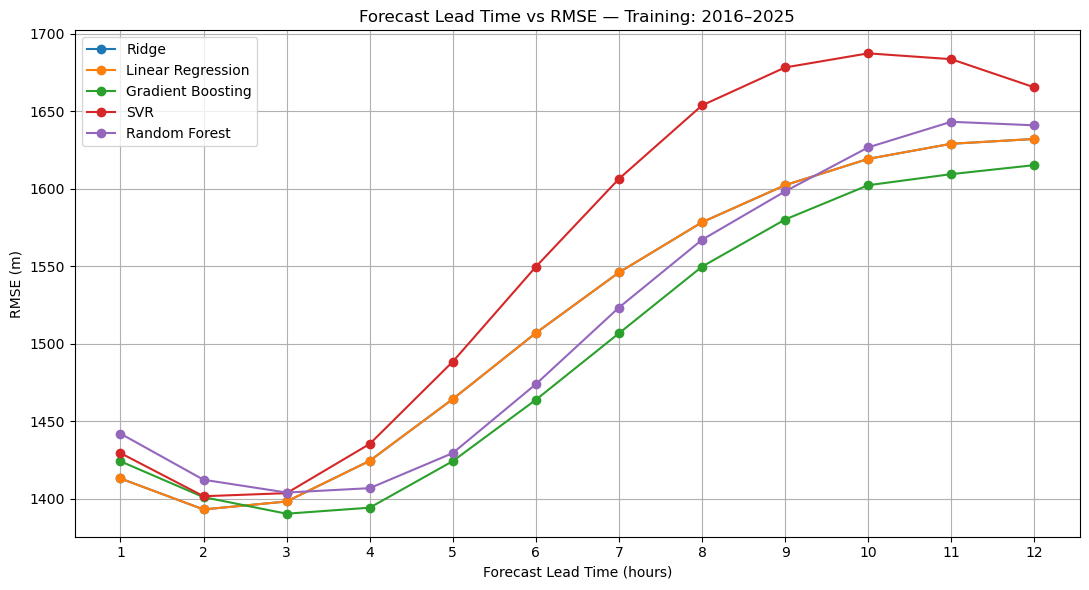

In [18]:
plt.figure(figsize=(11, 6))

for model in results_df["Model"].unique():

    model_data = results_df[
        results_df["Model"] == model
    ].sort_values("Lead Time (hours)")

    plt.plot(
        model_data["Lead Time (hours)"],
        model_data["RMSE"],
        marker="o",
        label=model
    )

plt.xlabel("Forecast Lead Time (hours)")
plt.ylabel("RMSE (m)")
plt.title("Forecast Lead Time vs RMSE — Training: 2016–2025")
plt.xticks(range(1, 13))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [19]:
# Winter months: November, December, January, February, March

winter_months = [11, 12, 1, 2, 3]

winter_train_df = train_df[
    train_df["Datetime"].dt.month.isin(winter_months)
].copy()

winter_train_df = winter_train_df.reset_index(drop=True)

print("Winter training data shape:", winter_train_df.shape)
print(
    "Training period:",
    winter_train_df["Datetime"].min(),
    "to",
    winter_train_df["Datetime"].max()
)

print("\nNumber of observations by month:")
print(
    winter_train_df["Datetime"]
    .dt.month
    .value_counts()
    .sort_index()
)

Winter training data shape: (34231, 30)
Training period: 2016-01-01 00:00:00 to 2025-12-31 11:00:00

Number of observations by month:
Datetime
1     6757
2     6469
3     7109
11    6828
12    7068
Name: count, dtype: int64


In [20]:
winter_results = []

winter_predictions = {}

for model_name, model_info in models.items():

    for lead_time in range(1, 13):

        print(
            f"Running {model_name} | "
            f"Winter Training | "
            f"{lead_time}-hour forecast"
        )

        result = run_forecast(
            train_df=winter_train_df,
            test_df=test_df,
            features=features,
            lead_time=lead_time,
            model=model_info["model"],
            scale=model_info["scale"]
        )

        winter_results.append({
            "Training Case": "Winter Months (Nov-Mar)",
            "Model": model_name,
            "Lead Time (hours)": lead_time,
            "MAE": result["MAE"],
            "MSE": result["MSE"],
            "RMSE": result["RMSE"],
            "R2": result["R2"]
        })

        key = f"{model_name}_{lead_time}h"

        winter_predictions[key] = {
            "Actual": result["Actual"],
            "Predicted": result["Predicted"]
        }

Running Linear Regression | Winter Training | 1-hour forecast
Running Linear Regression | Winter Training | 2-hour forecast
Running Linear Regression | Winter Training | 3-hour forecast
Running Linear Regression | Winter Training | 4-hour forecast
Running Linear Regression | Winter Training | 5-hour forecast
Running Linear Regression | Winter Training | 6-hour forecast
Running Linear Regression | Winter Training | 7-hour forecast
Running Linear Regression | Winter Training | 8-hour forecast
Running Linear Regression | Winter Training | 9-hour forecast
Running Linear Regression | Winter Training | 10-hour forecast
Running Linear Regression | Winter Training | 11-hour forecast
Running Linear Regression | Winter Training | 12-hour forecast
Running Ridge | Winter Training | 1-hour forecast
Running Ridge | Winter Training | 2-hour forecast
Running Ridge | Winter Training | 3-hour forecast
Running Ridge | Winter Training | 4-hour forecast
Running Ridge | Winter Training | 5-hour forecast
Run

In [21]:
winter_results_df = pd.DataFrame(winter_results)

winter_results_df

,Training Case,Model,Lead Time (hours),MAE,MSE,RMSE,R2
0,Winter Months (Nov-Mar),Linear Regression,1,1173.340455,2.067821e+06,1437.991886,0.119758
1,Winter Months (Nov-Mar),Linear Regression,2,1155.919267,1.997910e+06,1413.474542,0.149518
2,Winter Months (Nov-Mar),Linear Regression,3,1162.650740,2.028088e+06,1424.109470,0.136672
3,Winter Months (Nov-Mar),Linear Regression,4,1181.939689,2.146869e+06,1465.219884,0.086108
4,Winter Months (Nov-Mar),Linear Regression,5,1213.523436,2.329808e+06,1526.370969,0.008233
5,Winter Months (Nov-Mar),Linear Regression,6,1253.340866,2.533110e+06,1591.574630,-0.078309
6,Winter Months (Nov-Mar),Linear Regression,7,1299.109978,2.729111e+06,1652.002157,-0.161744
7,Winter Months (Nov-Mar),Linear Regression,8,1342.619482,2.898619e+06,1702.533011,-0.233901
8,Winter Months (Nov-Mar),Linear Regression,9,1381.788875,3.030389e+06,1740.801245,-0.289994
9,Winter Months (Nov-Mar),Linear Regression,10,1415.176018,3.126605e+06,1768.220882,-0.330952


In [ ]:
plt.figure(figsize=(11, 6))

for model in winter_results_df["Model"].unique():

    model_data = winter_results_df[
        winter_results_df["Model"] == model
    ].sort_values("Lead Time (hours)")

    plt.plot(
        model_data["Lead Time (hours)"],
        model_data["RMSE"],
        marker="o",
        label=model
    )

plt.xlabel("Forecast Lead Time (hours)")
plt.ylabel("RMSE (m)")
plt.title(
    "Forecast Lead Time vs RMSE — "
    "Winter Training (Nov–Mar), 2016–2025"
)

plt.xticks(range(1, 13))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Best-performing model for each forecast horizon
# Lower RMSE = better
winter_best_models = (
    winter_results_df
    .sort_values("RMSE")
    .groupby("Lead Time (hours)")
    .first()
    .reset_index()
)

winter_best_models[
    [
        "Lead Time (hours)",
        "Model",
        "MAE",
        "MSE",
        "RMSE",
        "R2"
    ]
]